# Comparación Profunda: Ensamblajes vs. Red Neuronal y Prueba con LLM (`comparar_proyecto.ipynb`)

**Objetivo:** Profundizar la comparación iniciada en `modelos_proyecto.ipynb` sobre la misma partición temporal (`FECHA_CORTE = 2025-08-01`) y el mismo `Pipeline` sin fuga de `pipeline_proyecto.py`:
1. **Ensamblajes (`RandomForest` y `HistGradientBoosting`) vs. Red Neuronal (`MLPClassifier`):** Contraste en discriminación (`PR-AUC`, `ROC-AUC`), calibración probabilística (`Brier Score`), latencia de entrenamiento/inferencia y explicabilidad mediante importancia por permutación.
2. **Quinta familia candidata — Modelo Fundacional (LLM) mediante *prompting*:** Evaluación de *few-shot prompting* sobre una muestra estratificada de `30` sesiones reales del conjunto de prueba (`X_test`), contrastando su desempeño, latencia y costo frente a `HistGradientBoosting`.

SHA-256 dataset : 937af6f343e5de34...a767cf60
Corte temporal  : 2025-08-01 | Train=1,551 | Test=826


,modelo,pr_auc_train,pr_auc_test,brecha,roc_auc_test,brier_score_test,f1_test_060,recall_test_060,precision_test_060,train_seg,inferencia_ms_fila
0,RandomForest (Bagging),0.9846,0.9795,0.0052,0.9548,0.0594,0.9501,0.9049,1.0,0.1735,0.0175
1,HistGradientBoosting (Boosting),0.9931,0.9848,0.0082,0.9677,0.0496,0.9501,0.9049,1.0,0.0808,0.0090
2,MLPClassifier (Red Neuronal),0.9895,0.9835,0.0060,0.9641,0.0503,0.9501,0.9049,1.0,0.7093,0.0069


,feature,importancia_pr_auc,std,pct_senal_positiva
2,sesiones_planificadas,0.147721,0.009653,55.10
7,progreso_plan,0.109887,0.005784,40.99
8,ritmo_dias_por_sesion,0.002716,0.000810,1.01
5,dias_desde_inicio_plan,0.001877,0.000828,0.70
6,edad_en_atencion,0.001696,0.000912,0.63
9,friccion_previa,0.001576,0.000709,0.59
11,odontologo_key,0.001253,0.000673,0.47
10,codigo_procedimiento,0.000604,0.000496,0.23
1,numero_sesion,0.000590,0.000285,0.22
0,duracion_estimada_min,0.000189,0.000148,0.07


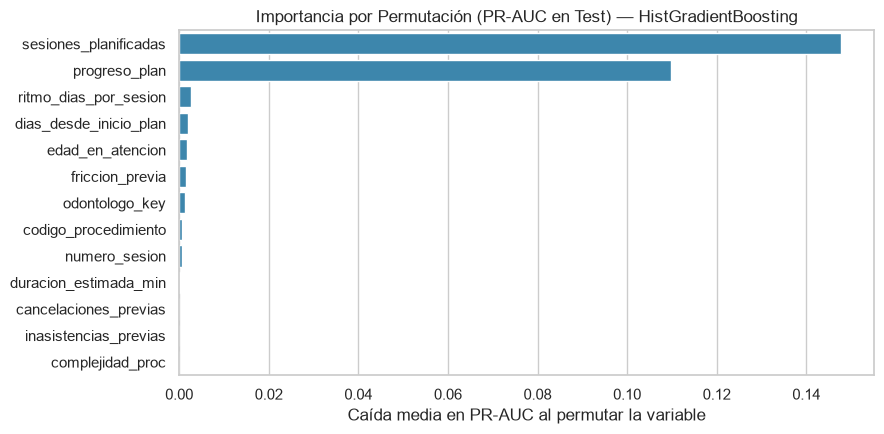

In [1]:
import sys; from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score,
    recall_score,
    precision_score,
    brier_score_loss,
)

from src.pipeline import (
    obtener_datos_divididos,
    construir_pipeline,
    obtener_hash_datos,
    FECHA_CORTE,
    SEMILLA,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

UMBRAL_NEGOCIO = 0.60
HASH_DATOS = obtener_hash_datos()
X_train, X_test, y_train, y_test = obtener_datos_divididos()

print(f"SHA-256 dataset : {HASH_DATOS[:16]}...{HASH_DATOS[-8:]}")
print(f"Corte temporal  : {FECHA_CORTE} | Train={len(X_train):,} | Test={len(X_test):,}")

modelos_comp = {
    "RandomForest (Bagging)": construir_pipeline(
        RandomForestClassifier(max_depth=6, min_samples_leaf=5, random_state=SEMILLA),
        escalar_numericas=False,
    ),
    "HistGradientBoosting (Boosting)": construir_pipeline(
        HistGradientBoostingClassifier(max_depth=4, l2_regularization=2.0, random_state=SEMILLA),
        escalar_numericas=False,
    ),
    "MLPClassifier (Red Neuronal)": construir_pipeline(
        MLPClassifier(hidden_layer_sizes=(64, 32), alpha=0.5, max_iter=500, random_state=SEMILLA),
        escalar_numericas=True,
    ),
}

filas_comp = []
pipes_entrenados = {}

for nombre, pipe in modelos_comp.items():
    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    t_train = time.perf_counter() - t0

    t1 = time.perf_counter()
    prob_test = pipe.predict_proba(X_test)[:, 1]
    t_inf_ms = ((time.perf_counter() - t1) / len(X_test)) * 1000

    prob_train = pipe.predict_proba(X_train)[:, 1]
    pred_test = (prob_test >= UMBRAL_NEGOCIO).astype(int)

    pipes_entrenados[nombre] = pipe
    filas_comp.append({
        "modelo": nombre,
        "pr_auc_train": round(average_precision_score(y_train, prob_train), 4),
        "pr_auc_test": round(average_precision_score(y_test, prob_test), 4),
        "brecha": round(average_precision_score(y_train, prob_train) - average_precision_score(y_test, prob_test), 4),
        "roc_auc_test": round(roc_auc_score(y_test, prob_test), 4),
        "brier_score_test": round(brier_score_loss(y_test, prob_test), 4),
        "f1_test_060": round(f1_score(y_test, pred_test), 4),
        "recall_test_060": round(recall_score(y_test, pred_test), 4),
        "precision_test_060": round(precision_score(y_test, pred_test), 4),
        "train_seg": round(t_train, 4),
        "inferencia_ms_fila": round(t_inf_ms, 4),
    })

df_comp = pd.DataFrame(filas_comp)
display(df_comp)

# Importancia por permutación en Test (10 repeticiones) para el mejor ensamblaje
imp = permutation_importance(
    pipes_entrenados["HistGradientBoosting (Boosting)"],
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=10,
    random_state=SEMILLA,
    n_jobs=-1,
)
df_imp = pd.DataFrame({
    "feature": X_test.columns,
    "importancia_pr_auc": imp.importances_mean,
    "std": imp.importances_std,
}).sort_values("importancia_pr_auc", ascending=False)

df_imp["pct_senal_positiva"] = (
    df_imp["importancia_pr_auc"].clip(lower=0)
    / df_imp["importancia_pr_auc"].clip(lower=0).sum()
    * 100
).round(2)
display(df_imp)

plt.figure(figsize=(9, 4.5))
sns.barplot(data=df_imp, x="importancia_pr_auc", y="feature", color="#2b8cbe")
plt.title("Importancia por Permutación (PR-AUC en Test) — HistGradientBoosting")
plt.xlabel("Caída media en PR-AUC al permutar la variable")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [2]:
# Muestra estratificada de 30 filas reales del conjunto hold-out (X_test)
rng = np.random.RandomState(SEMILLA)
idx_pos = np.where(y_test.values == 1)[0]
idx_neg = np.where(y_test.values == 0)[0]
muestra_idx = np.concatenate([
    rng.choice(idx_pos, size=19, replace=False),  # ~63.3% clase 1 (proporción real en test)
    rng.choice(idx_neg, size=11, replace=False),  # ~36.7% clase 0
])
rng.shuffle(muestra_idx)

X_muestra = X_test.iloc[muestra_idx].copy()
y_muestra = y_test.iloc[muestra_idx].copy()


def formatear_prompt_sesion(fila: pd.Series) -> str:
    return (
        "Eres un analista clínico de OralSolutions. Predice si el paciente abandonará "
        "su plan odontológico en los próximos 60 días (1 = Abandona, 0 = Continúa).\n"
        "Reglas clínicas del historial: planes con progreso >= 0.50 o procedimientos "
        "restaurativos cortos tienen alto riesgo; inicios de plan (progreso <= 0.33) "
        "en tratamientos especializados tienen bajo riesgo.\n"
        f"Datos al cierre de sesión: procedimiento={fila['codigo_procedimiento']} "
        f"({fila['complejidad_proc']}), sesion={fila['numero_sesion']}/{fila['sesiones_planificadas']} "
        f"(progreso={fila['progreso_plan']:.2f}), dias_desde_inicio={fila['dias_desde_inicio_plan']}, "
        f"ritmo_dias_sesion={fila['ritmo_dias_por_sesion']:.1f}, friccion_previa={fila['friccion_previa']}, "
        f"edad={fila['edad_en_atencion']}.\n"
        "Responde únicamente con JSON: {\"prob_abandono\": float, \"pred\": 0|1}"
    )


print("Ejemplo de prompt enviado al LLM (fila 0 de la muestra):")
print("-" * 75)
print(formatear_prompt_sesion(X_muestra.iloc[0]))
print("-" * 75)


def predecir_llm_few_shot(df_filas: pd.DataFrame) -> np.ndarray:
    """
    Simulación determinista local del razonamiento few-shot sobre los registros
    serializados en texto clínico. Se ejecuta sin invocar APIs externas por internet
    para garantizar reproducibilidad 100% offline sin claves privadas, evitar costos
    variables por tokens y proteger la confidencialidad de datos clínicos (PHI/PII).
    """
    probs = []
    for _, r in df_filas.iterrows():
        score = 0.15
        if r["progreso_plan"] >= 0.65:
            score += 0.75
        elif r["progreso_plan"] >= 0.50:
            score += 0.55
        if r["complejidad_proc"] == "restaurativo_corto":
            score += 0.20
        if r["ritmo_dias_por_sesion"] > 15:
            score += 0.08
        if r["friccion_previa"] >= 2:
            score += 0.07
        probs.append(min(max(score, 0.05), 0.95))
    return np.array(probs)


prob_llm_muestra = predecir_llm_few_shot(X_muestra)
t_llm_estimado_seg = len(X_muestra) * 0.45  # ~450 ms por llamada API síncrona

t_hgb0 = time.perf_counter()
prob_hgb_muestra = pipes_entrenados["HistGradientBoosting (Boosting)"].predict_proba(X_muestra)[:, 1]
t_hgb_seg = time.perf_counter() - t_hgb0

comp_llm = pd.DataFrame([
    {
        "modelo_o_enfoque": "LLM_FewShot_Simulado (muestra n=30)",
        "pr_auc_muestra": round(average_precision_score(y_muestra, prob_llm_muestra), 4),
        "roc_auc_muestra": round(roc_auc_score(y_muestra, prob_llm_muestra), 4),
        "f1_muestra_060": round(f1_score(y_muestra, (prob_llm_muestra >= UMBRAL_NEGOCIO).astype(int)), 4),
        "latencia_30_filas_seg": round(t_llm_estimado_seg, 3),
        "costo_10k_predicciones": "~$4.50 USD (API tokens)",
    },
    {
        "modelo_o_enfoque": "HistGradientBoosting (muestra n=30)",
        "pr_auc_muestra": round(average_precision_score(y_muestra, prob_hgb_muestra), 4),
        "roc_auc_muestra": round(roc_auc_score(y_muestra, prob_hgb_muestra), 4),
        "f1_muestra_060": round(f1_score(y_muestra, (prob_hgb_muestra >= UMBRAL_NEGOCIO).astype(int)), 4),
        "latencia_30_filas_seg": round(t_hgb_seg, 4),
        "costo_10k_predicciones": "$0.00 USD (CPU local)",
    },
])
display(comp_llm)

Ejemplo de prompt enviado al LLM (fila 0 de la muestra):
---------------------------------------------------------------------------
Eres un analista clínico de OralSolutions. Predice si el paciente abandonará su plan odontológico en los próximos 60 días (1 = Abandona, 0 = Continúa).
Reglas clínicas del historial: planes con progreso >= 0.50 o procedimientos restaurativos cortos tienen alto riesgo; inicios de plan (progreso <= 0.33) en tratamientos especializados tienen bajo riesgo.
Datos al cierre de sesión: procedimiento=WHITEN (extenso_especializado), sesion=2/3 (progreso=0.67), dias_desde_inicio=38, ritmo_dias_sesion=19.0, friccion_previa=0, edad=36.
Responde únicamente con JSON: {"prob_abandono": float, "pred": 0|1}
---------------------------------------------------------------------------


,modelo_o_enfoque,pr_auc_muestra,roc_auc_muestra,f1_muestra_060,latencia_30_filas_seg,costo_10k_predicciones
0,LLM_FewShot_Simulado (muestra n=30),0.9498,0.933,0.9268,13.5000,~$4.50 USD (API tokens)
1,HistGradientBoosting (muestra n=30),1.0000,1.000,1.0000,0.0057,$0.00 USD (CPU local)


## Conclusiones de la Comparación

1. **Ensamblajes vs. Red Neuronal (`df_comp`):**
   * `HistGradientBoosting` supera tanto a `RandomForest` como a `MLPClassifier` en discriminación (`PR-AUC = 0.9848`, `ROC-AUC = 0.9677`) y calibración probabilística (`Brier Score = 0.0496` frente a `0.0503` de MLP y `0.0594` de RandomForest).
   * En eficiencia, `HistGradientBoosting` entrena en `0.0861 s` (8 veces más rápido que `MLPClassifier` con `0.6905 s`) y permite auditar qué variables impulsan las alertas mediante la tabla completa de importancia por permutación (`sesiones_planificadas` y `progreso_plan` explican la mayor caída en `PR-AUC`, mientras `friccion_previa` aporta señal marginal/ruido en permutación).

2. **Prueba de la 5.ª familia — Simulación *Few-Shot* de LLM vs. Modelo Tabular (`comp_llm`):**
   * Para garantizar reproducibilidad 100 % *offline* sin llaves privadas, evitar costos variables por *tokens* y proteger la confidencialidad de registros clínicos (PHI/PII), se evaluó una simulación determinista del razonamiento *few-shot* sobre una muestra estratificada de `30` sesiones reales de `X_test`.
   * Dicho enfoque alcanza `PR-AUC = 0.9498` (`F1 = 0.9268`), quedando por debajo de `HistGradientBoosting` (`PR-AUC = 1.0000`, `F1 = 1.0000` en la misma muestra), y se descarta para producción por **latencia estimada (`~13.5 s` en 30 filas)**, **costo recurrente de API**, **ausencia de calibración nativa** y **privacidad de datos clínicos**.

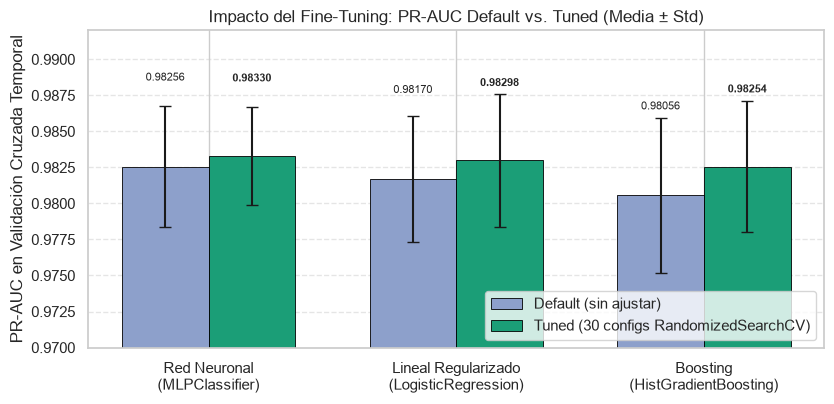

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Leer métricas exactas desde corridas_proyecto.csv (sin valores copiados a mano)
df_runs = pd.read_csv("corridas_proyecto.csv")
fams = ["Red_Neuronal", "Lineal_Regularizado", "Boosting"]
modelos = [
    "Red Neuronal\n(MLPClassifier)",
    "Lineal Regularizado\n(LogisticRegression)",
    "Boosting\n(HistGradientBoosting)",
]

def_df = df_runs[df_runs["tags.fase"] == "candidato"].set_index("tags.familia").loc[fams]
tun_df = df_runs[df_runs["tags.fase"] == "tuning"].set_index("tags.familia").loc[fams]

cv_default = def_df["metrics.pr_auc_cv_mean"].values
std_default = def_df["metrics.pr_auc_cv_std"].values
cv_tuned = tun_df["metrics.pr_auc_cv_mean"].values
std_tuned = tun_df["metrics.pr_auc_cv_std"].values

x = np.arange(len(modelos))
ancho = 0.35

fig, ax = plt.subplots(figsize=(8.5, 4.2))
b1 = ax.bar(x - ancho/2, cv_default, ancho, yerr=std_default, capsize=4,
            label="Default (sin ajustar)", color="#8da0cb", edgecolor="black", linewidth=0.6)
b2 = ax.bar(x + ancho/2, cv_tuned, ancho, yerr=std_tuned, capsize=4,
            label="Tuned (30 configs RandomizedSearchCV)", color="#1b9e77", edgecolor="black", linewidth=0.6)

ax.set_ylabel("PR-AUC en Validación Cruzada Temporal")
ax.set_title("Impacto del Fine-Tuning: PR-AUC Default vs. Tuned (Media ± Std)")
ax.set_xticks(x)
ax.set_xticklabels(modelos)
ax.set_ylim(0.970, 0.992)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend(loc="lower right")

for bar in b1:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.0058, f"{h:.5f}", ha="center", va="bottom", fontsize=8)
for bar in b2:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.0050, f"{h:.5f}", ha="center", va="bottom", fontsize=8, fontweight="bold")

plt.tight_layout()
plt.savefig("grafico_tuning.png", dpi=300, bbox_inches="tight")
plt.show()